# Paper tables and figure

This notebook rebuilds the results tables and the figure of the camera-ready paper
*From Temporal Foundation to World Models: Counterfactual Probing with Exact
Ground Truth* (FMTS workshop, NeurIPS 2026). 

**Inputs** (`results/metrics/`)

| File | Used for |
|---|---|
| `summary_pooled_nonzero.csv` | Identifiability headline: Table 1, Table 5 (Identifiability columns), Appendix E.6 |
| `summary_by_structure.csv`, `summary_by_structure_nonzero.csv` | Table 4 |
| `summary_pooled.csv` | Continuous suite: Tables 5 and 7, Appendix E.6 |
| `per_episode.csv` | Effect Profiles: Tables 6, 8, 9 and Figure 1 |

**Outputs.** Tables as CSV files in `results/paper_artifacts/`, and the two
panels of Figure 1 in `results/figures/`.

**Evaluation populations.**

- *Identifiability headline:* the 5,165 episodes with a nonzero true effect at
  the query. The other 5,635 are null controls, on which the zero-effect
  anchor is exact by construction; Table 4 reports them separately.
- *Continuous:* the frozen selections in `results/selections/`, 1,000
  non-self episodes per structure for each of the in-window and post-window
  regimes.

## Setup

In [1]:
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "results").exists() and (ROOT.parent / "results").exists():
    ROOT = ROOT.parent

METRICS = ROOT / "results" / "metrics"
TABLES = ROOT / "results" / "paper_artifacts"
FIGURES = ROOT / "results" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

pooled = pd.read_csv(METRICS / "summary_pooled.csv")
pooled_nz = pd.read_csv(METRICS / "summary_pooled_nonzero.csv")
by_structure = pd.read_csv(METRICS / "summary_by_structure.csv")
by_structure_nz = pd.read_csv(METRICS / "summary_by_structure_nonzero.csv")

# Per-episode rows are needed only for the Effect Profiles.
PER_EPISODE = METRICS / "per_episode.csv"
per_episode = pd.read_csv(PER_EPISODE, low_memory=False) if PER_EPISODE.exists() else None
print("per_episode.csv:",
      f"{len(per_episode):,} rows" if per_episode is not None
      else "not found; run aggregate_metrics.py to build Tables 6, 8, 9 and Figure 1")

per_episode.csv: 228,000 rows


In [2]:
MODELS = ["chronos-2", "tabpfn-ts", "tirex-2", "moirai-1.1", "moirai-2.0", "timesfm-2.5"]
DISPLAY = {
    "chronos-2": "Chronos-2", "tabpfn-ts": "TabPFN-TS", "tirex-2": "TiRex-2",
    "moirai-1.1": "Moirai-1.1", "moirai-2.0": "Moirai-2.0", "timesfm-2.5": "TimesFM-2.5",
    "dotime-pfn": "DoT-PFN", "tabpfn-static-adjustment": "Static TabPFN",
}
INTERFACE = {m: "P1" for m in MODELS} | {"timesfm-2.5": "P1*"}
ANCHOR = "zero"  # TrajMean, AR(1) and Zero all imply a zero effect
EM = "—"


def row(model, regime, source=pooled):
    # One summary row, or None if the model was not run in that regime.
    x = source[(source.model == model) & (source.regime == regime)]
    return None if x.empty else x.iloc[0]


def ci(r, metric):
    # "value [lo, hi]" with the 95% percentile-bootstrap interval.
    if r is None or not np.isfinite(r.get(metric, np.nan)):
        return EM
    return f"{r[metric]:.3f} [{r[metric + '_lo']:.3f}, {r[metric + '_hi']:.3f}]"


def pt(r, metric):
    # Point estimate only.
    if r is None or not np.isfinite(r.get(metric, np.nan)):
        return EM
    return f"{r[metric]:.3f}"


def save(df, name, styled=None):
    df.to_csv(TABLES / f"{name}.csv")
    print("Saved:", TABLES / f"{name}.csv")
    display(styled if styled is not None else df)

## Table 1 — Identifiability headline

Computed on the 5,165 nonzero-effect episodes. Effect Delta RMSE is the primary
metric, and a model carries causal information only if it falls below the
zero-effect anchor. Direction accuracy is scored on episodes with |τ| ≥ 0.1,
and coverage is read against its nominal 0.80.

In [5]:
rows = []
for model in MODELS:
    r = row(model, "identifiability", pooled_nz)
    rows.append({
        "Model": DISPLAY[model],
        "Interface": INTERFACE[model],
        "Usage Gap": ci(r, "usage_gap"),
        "Effect Delta RMSE ↓": ci(r, "effect_rmse"),
        "Dir. Acc. ↑": ci(r, "direction_accuracy"),
        "Cov. 80%": ci(r, "coverage_80"),
    })

anchor = row(ANCHOR, "identifiability", pooled_nz)
rows.append({
    "Model": "Zero-effect anchors", "Interface": EM,
    "Usage Gap": ci(anchor, "usage_gap"),
    "Effect Delta RMSE ↓": ci(anchor, "effect_rmse"),
    "Dir. Acc. ↑": EM, "Cov. 80%": EM,
})

table1 = pd.DataFrame(rows).set_index("Model")
save(table1, "table1_identifiability")
print(f"Episodes: {int(anchor.n):,} | scored for direction: "
      f"{int(row('chronos-2', 'identifiability', pooled_nz).direction_n_scored):,}")

Saved: /home/labian-3/Documentos/Fernanda/TSFMs/results/paper_artifacts/table1_identifiability.csv


,Interface,Usage Gap,Effect Delta RMSE ↓,Dir. Acc. ↑,Cov. 80%
Model,,,,,
Chronos-2,P1,"0.194 [0.183, 0.205]","0.471 [0.447, 0.496]","0.807 [0.793, 0.821]","0.720 [0.708, 0.733]"
TabPFN-TS,P1,"0.185 [0.178, 0.192]","0.504 [0.468, 0.540]","0.848 [0.835, 0.860]","0.758 [0.747, 0.770]"
TiRex-2,P1,"0.200 [0.187, 0.213]","0.482 [0.455, 0.510]","0.746 [0.731, 0.761]","0.682 [0.669, 0.694]"
Moirai-1.1,P1,"0.032 [0.031, 0.033]","0.676 [0.634, 0.720]","0.504 [0.494, 0.514]","0.574 [0.561, 0.587]"
Moirai-2.0,P1,"0.007 [0.006, 0.007]","0.674 [0.631, 0.717]","0.491 [0.473, 0.508]","0.593 [0.580, 0.607]"
TimesFM-2.5,P1*,"0.482 [0.463, 0.503]","0.565 [0.509, 0.632]","0.862 [0.850, 0.874]","0.638 [0.625, 0.652]"
Zero-effect anchors,—,"0.000 [0.000, 0.000]","0.674 [0.631, 0.717]",—,—


Episodes: 5,165 | scored for direction: 3,194


### Response scale (RQ2)

RQ2 compares each model's Usage Gap with the mean absolute true effect E[|τ|]
on the same 5,165 episodes. A ratio near 1 means the model moves its forecast
by about as much as the intervention moves the outcome.

In [ ]:
scale = anchor.true_effect_scale
print(f"E[|tau|] = {scale:.3f}")

rq2 = pd.Series(
    {DISPLAY[m]: row(m, "identifiability", pooled_nz).usage_gap / scale for m in MODELS},
    name="Usage Gap / E[|tau|]",
)
display(rq2.round(3).to_frame())

E[|tau|] = 0.369


,Usage Gap / E[|tau|]
Chronos-2,0.524
TabPFN-TS,0.501
TiRex-2,0.542
Moirai-1.1,0.087
Moirai-2.0,0.019
TimesFM-2.5,1.306


## Table 4 — Identifiability by causal structure

At the query step the true effect is exactly zero in every mediator,
observed-confounder and unobserved-confounder episode. These three structures
are kept with all their episodes as null controls. The other five structures
also contain null episodes (15–34%); those are removed so that the anchor is not
favoured by construction, and the five columns together form the 5,165-episode
population of Table 1. The row `n` gives the episodes behind each column.

In [9]:
STRUCTURES = [
    ("bi_variate", "Bivariate"), ("mediator", "Mediator"),
    ("observed_confounder", "Obs. conf."), ("unobserved_confounder", "Unobs. conf."),
    ("back_door", "Back-door"), ("front_door", "Front-door"),
    ("instrumental_variable", "IV"), ("confounder_mediator", "Conf. + med."),
]
NULL_STRUCTURES = {"mediator", "observed_confounder", "unobserved_confounder"}

# Null controls from the full suite, the other structures from nonzero-effect episodes.
full = by_structure[by_structure.regime == "identifiability"]
nonzero = by_structure_nz[by_structure_nz.regime == "identifiability"]
ident_structure = pd.concat([
    full[full.structure.isin(NULL_STRUCTURES)],
    nonzero[~nonzero.structure.isin(NULL_STRUCTURES)],
], ignore_index=True)


def structure_value(model, structure, column):
    x = ident_structure[(ident_structure.model == model) & (ident_structure.structure == structure)]
    return np.nan if x.empty else x.iloc[0][column]


TABLE4_ROWS = [(m, DISPLAY[m]) for m in MODELS] + [
    (ANCHOR, "TrajMean / AR(1) / Zero"),
    ("tabpfn-static-adjustment", "Static TabPFN"),  # reports its own effect estimate
]
table4 = pd.DataFrame(
    [[structure_value(ANCHOR, s, "n") for s, _ in STRUCTURES]]
    + [[structure_value(model, s, "reference_effect_rmse" if model == "tabpfn-static-adjustment"
                        else "effect_rmse") for s, _ in STRUCTURES]
       for model, _ in TABLE4_ROWS],
    index=["n"] + [label for _, label in TABLE4_ROWS],
    columns=[col for _, col in STRUCTURES],
)
table4.index.name = "Model"
save(table4, "table4_effect_rmse_by_structure",
     styled=table4.style.format("{:.3f}").format("{:,.0f}", subset=pd.IndexSlice[["n"], :]))

Saved: /home/labian-3/Documentos/Fernanda/TSFMs/results/paper_artifacts/table4_effect_rmse_by_structure.csv


,Bivariate,Mediator,Obs. conf.,Unobs. conf.,Back-door,Front-door,IV,Conf. + med.
Model,,,,,,,,
n,"1,146","1,350","1,350","1,350","1,091",898,"1,139",891
Chronos-2,0.549,0.082,0.095,0.156,0.566,0.288,0.515,0.293
TabPFN-TS,0.560,0.116,0.088,0.117,0.644,0.260,0.563,0.299
TiRex-2,0.504,0.075,0.100,0.139,0.613,0.330,0.521,0.322
Moirai-1.1,0.775,0.044,0.060,0.040,0.858,0.306,0.769,0.352
Moirai-2.0,0.772,0.013,0.013,0.012,0.854,0.307,0.768,0.349
TimesFM-2.5,0.520,0.309,0.291,0.363,0.760,0.548,0.500,0.413
TrajMean / AR(1) / Zero,0.772,0.000,0.000,0.000,0.853,0.305,0.769,0.350
Static TabPFN,0.772,0.061,0.079,0.000,0.583,0.252,0.769,0.259


### Null-effect episodes per structure

The counts behind the 5,635 null controls and the 5,165-episode headline.

In [10]:
total = full[full.model == ANCHOR].set_index("structure")["n"]
with_effect = (nonzero[nonzero.model == ANCHOR].set_index("structure")["n"]
               .reindex(total.index, fill_value=0))

null_counts = pd.DataFrame({"episodes": total, "nonzero effect": with_effect,
                            "null": total - with_effect})
null_counts["null fraction"] = (null_counts["null"] / null_counts["episodes"]).round(3)
display(null_counts.loc[[s for s, _ in STRUCTURES]].astype({"episodes": int, "nonzero effect": int, "null": int}))
print(f"Null episodes: {int(null_counts['null'].sum()):,} | "
      f"nonzero-effect episodes: {int(null_counts['nonzero effect'].sum()):,}")

,episodes,nonzero effect,null,null fraction
structure,,,,
bi_variate,1350,1146,204,0.151
mediator,1350,0,1350,1.000
observed_confounder,1350,0,1350,1.000
unobserved_confounder,1350,0,1350,1.000
back_door,1350,1091,259,0.192
front_door,1350,898,452,0.335
instrumental_variable,1350,1139,211,0.156
confounder_mediator,1350,891,459,0.340


Null episodes: 5,635 | nonzero-effect episodes: 5,165


## Table 5 — Probabilistic calibration

Identifiability columns use the 5,165 nonzero-effect episodes of Table 1; the
Continuous columns use the frozen selections. Coverage is read against 0.80,
and lower CRPS is better.

In [11]:
REGIMES = [
    ("identifiability", "Identifiability", pooled_nz),
    ("in_window", "Continuous In-window", pooled),
    ("post_window", "Continuous Post-window", pooled),
]
CAL_MODELS = MODELS + ["dotime-pfn"]

data = []
for model in CAL_MODELS:
    values = []
    for regime, _, source in REGIMES:
        r = row(model, regime, source)
        values += [ci(r, "coverage_80"), ci(r, "crps_approx")]
    data.append(values)

table5 = pd.DataFrame(
    data,
    index=pd.Index([DISPLAY[m] for m in CAL_MODELS], name="Model"),
    columns=pd.MultiIndex.from_product([[label for _, label, _ in REGIMES], ["80% Cov.", "CRPS ↓"]]),
)
save(table5, "table5_calibration")

Saved: /home/labian-3/Documentos/Fernanda/TSFMs/results/paper_artifacts/table5_calibration.csv


Identifiability                        Continuous In-window  \
                         80% Cov.                CRPS ↓              80% Cov.   
Model                                                                           
Chronos-2    0.720 [0.708, 0.733]  0.323 [0.314, 0.332]  0.793 [0.778, 0.807]   
TabPFN-TS    0.758 [0.747, 0.770]  0.333 [0.323, 0.344]  0.677 [0.660, 0.694]   
TiRex-2      0.682 [0.669, 0.694]  0.327 [0.317, 0.336]  0.715 [0.699, 0.731]   
Moirai-1.1   0.574 [0.561, 0.587]  0.429 [0.415, 0.444]  0.717 [0.701, 0.732]   
Moirai-2.0   0.593 [0.580, 0.607]  0.419 [0.405, 0.433]  0.673 [0.656, 0.690]   
TimesFM-2.5  0.638 [0.625, 0.652]  0.356 [0.344, 0.369]  0.593 [0.576, 0.611]   
DoT-PFN      0.659 [0.646, 0.673]  0.433 [0.419, 0.447]  0.797 [0.783, 0.812]   

                                  Continuous Post-window                        
                           CRPS ↓               80% Cov.                CRPS ↓  
Model                                                                           
Chronos-2    0.578 [0.541, 0.626]   0.838 [0.825, 0.852]  0.645 [0.547, 0.794]  
TabPFN-TS    0.827 [0.723, 0.979]   0.860 [0.847, 0.872]  0.641 [0.548, 0.770]  
TiRex-2      0.669 [0.614, 0.749]   0.809 [0.795, 0.823]  0.643 [0.555, 0.772]  
Moirai-1.1   0.663 [0.617, 0.715]                      —                     —  
Moirai-2.0   0.639 [0.601, 0.683]                      —                     —  
TimesFM-2.5  0.896 [0.812, 1.006]                      —                     —  
DoT-PFN      0.718 [0.652, 0.803]   0.871 [0.859, 0.883]  0.665 [0.563, 0.809]

## Effect Profile helpers

The Effect Profile bins Continuous episodes by query offset: steps since the
intervention onset in-window (`q - t_start`), and steps since the window ended
post-window (`q - t_end`). Within each 10-step bin it reports the Effect Delta
MAE. For Moirai-1.1, errors are averaged over the three seeds per episode
before bootstrapping. Intervals use 10,000 episode resamples with seed 42.
The zero-effect anchor in each bin equals the mean absolute true effect.

In [12]:
IN_EDGES = [0, 10, 20, 30, 40, 50, 60]
IN_LABELS = ["0–9", "10–19", "20–29", "30–39", "40–49", "50–59"]
POST_EDGES = [0, 10, 20, 30, 40, 50, 60, 70, 80, np.inf]
POST_LABELS = ["0–9", "10–19", "20–29", "30–39", "40–49", "50–59", "60–69", "70–79", "80+"]


def bins_for(regime):
    return (IN_EDGES, IN_LABELS) if regime == "in_window" else (POST_EDGES, POST_LABELS)


def episodes_for(regime, model=None):
    if per_episode is None:
        raise FileNotFoundError("results/metrics/per_episode.csv is missing; run aggregate_metrics.py first.")
    d = per_episode[per_episode.regime == regime]
    d = d[d.model == model] if model is not None else d.drop_duplicates("episode")
    d = d.copy()
    d["offset"] = (d.query_offset_from_start if regime == "in_window"
                   else d.query_step - d.intervention_end)
    edges, labels = bins_for(regime)
    d["bin"] = pd.cut(d.offset, edges, labels=labels, right=False)
    return d


def bootstrap_mean(x, n_boot=10_000, seed=42, block=500):
    # Mean with a 95% percentile-bootstrap interval; returns (mean, lo, hi, n).
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    rng = np.random.default_rng(seed)
    reps = []
    for start in range(0, n_boot, block):
        idx = rng.integers(0, len(x), size=(min(block, n_boot - start), len(x)))
        reps.append(x[idx].mean(axis=1))
    lo, hi = np.percentile(np.concatenate(reps), [2.5, 97.5])
    return x.mean(), lo, hi, len(x)


@lru_cache(maxsize=None)
def profile_data(regime, model, nonzero=False):
    # Effect Delta MAE per offset bin for one model.
    d = episodes_for(regime, model)
    d["error"] = (d.implied_effect_metric - d.true_effect).abs()
    if nonzero:
        d = d[d.true_effect != 0]
    per_ep = d.groupby(["episode", "bin"], observed=True).error.mean().reset_index()
    return {b: bootstrap_mean(per_ep.loc[per_ep.bin == b, "error"]) for b in bins_for(regime)[1]}


@lru_cache(maxsize=None)
def truth_profile(regime, nonzero=False):
    # Mean |true effect| per bin, i.e. the zero-effect anchor, with the bin counts.
    d = episodes_for(regime)
    if nonzero:
        d = d[d.true_effect != 0]
    return {b: bootstrap_mean(d.loc[d.bin == b, "true_effect"].abs()) for b in bins_for(regime)[1]}


def profile_table(regime, models, nonzero=False, with_ci=False):
    labels = bins_for(regime)[1]
    rows = {}
    for model, label in models:
        vals = profile_data(regime, model, nonzero)
        rows[label] = [f"{vals[b][0]:.3f} [{vals[b][1]:.3f}, {vals[b][2]:.3f}]" if with_ci
                       else vals[b][0] for b in labels]
    table = pd.DataFrame.from_dict(rows, orient="index", columns=labels)
    table.index.name = "Model"
    return table, truth_profile(regime, nonzero)


def counts_style(table, count_rows):
    # Three decimals for errors, integers for the episode-count rows.
    return (table.style.format("{:.3f}", na_rep=EM)
            .format("{:,.0f}", subset=pd.IndexSlice[count_rows, :]))

## Table 6 — Continuous in-window Effect Profile

Effect Delta MAE by steps since the intervention onset, with 95% intervals.

In [13]:
table6, anchor_in = profile_table("in_window", [(m, DISPLAY[m]) for m in MODELS], with_ci=True)
table6.loc["Zero-effect anchor"] = [f"{anchor_in[b][0]:.3f}" for b in IN_LABELS]
table6.loc["n episodes"] = [anchor_in[b][3] for b in IN_LABELS]
save(table6, "table6_in_window_effect_profile")

Saved: /home/labian-3/Documentos/Fernanda/TSFMs/results/paper_artifacts/table6_in_window_effect_profile.csv


,0–9,10–19,20–29,30–39,40–49,50–59
Model,,,,,,
Chronos-2,"0.381 [0.341, 0.422]","0.526 [0.465, 0.590]","0.618 [0.510, 0.763]","0.547 [0.453, 0.653]","0.610 [0.495, 0.737]","0.461 [0.333, 0.611]"
TabPFN-TS,"0.720 [0.552, 0.973]","0.733 [0.638, 0.834]","0.986 [0.698, 1.440]","0.757 [0.589, 0.946]","0.679 [0.544, 0.825]","0.605 [0.436, 0.789]"
TiRex-2,"0.449 [0.393, 0.509]","0.648 [0.570, 0.733]","0.685 [0.561, 0.837]","0.558 [0.465, 0.664]","0.620 [0.497, 0.761]","0.478 [0.338, 0.632]"
Moirai-1.1,"0.385 [0.335, 0.437]","0.543 [0.466, 0.628]","0.627 [0.456, 0.906]","0.471 [0.381, 0.576]","0.512 [0.400, 0.635]","0.379 [0.262, 0.513]"
Moirai-2.0,"0.360 [0.310, 0.412]","0.526 [0.448, 0.612]","0.613 [0.429, 0.919]","0.468 [0.383, 0.562]","0.504 [0.392, 0.630]","0.400 [0.281, 0.534]"
TimesFM-2.5,"0.755 [0.631, 0.911]","0.884 [0.771, 1.006]","1.050 [0.792, 1.426]","0.819 [0.670, 0.985]","0.804 [0.656, 0.966]","0.710 [0.499, 0.943]"
Zero-effect anchor,0.356,0.516,0.594,0.441,0.467,0.366
n episodes,797,749,690,436,257,71


## Table 7 — Aggregate Continuous results

In-window and post-window are separate regimes and are compared within regime.
Moirai and TimesFM are not eligible post-window (Appendix C).

In [14]:
rows = []
for model, label in [(m, DISPLAY[m]) for m in MODELS] + [(ANCHOR, "Zero-effect anchor")]:
    out = {"Model": label}
    for regime, prefix in [("in_window", "In-window"), ("post_window", "Post-window")]:
        r = row(model, regime)
        out[(prefix, "Usage Gap")] = pt(r, "usage_gap")
        out[(prefix, "Effect Delta RMSE ↓")] = ci(r, "effect_rmse")
        out[(prefix, "Effect Delta MAE ↓")] = ci(r, "effect_mae")
    rows.append(out)

table7 = pd.DataFrame(rows).set_index("Model")
table7.columns = pd.MultiIndex.from_tuples(table7.columns)
save(table7, "table7_aggregate_continuous")

Saved: /home/labian-3/Documentos/Fernanda/TSFMs/results/paper_artifacts/table7_aggregate_continuous.csv


In-window                                              \
                   Usage Gap   Effect Delta RMSE ↓    Effect Delta MAE ↓   
Model                                                                      
Chronos-2              0.395  1.210 [0.946, 1.556]  0.517 [0.480, 0.558]   
TabPFN-TS              0.406  3.206 [1.642, 4.744]  0.784 [0.686, 0.906]   
TiRex-2                0.358  1.379 [1.129, 1.697]  0.584 [0.541, 0.630]   
Moirai-1.1             0.091  1.833 [1.033, 2.761]  0.503 [0.450, 0.573]   
Moirai-2.0             0.042  1.915 [0.990, 2.964]  0.488 [0.432, 0.563]   
TimesFM-2.5            0.648  2.688 [1.760, 3.773]  0.867 [0.784, 0.963]   
Zero-effect anchor     0.000  1.896 [0.980, 2.936]  0.473 [0.417, 0.547]   

                   Post-window                                              
                     Usage Gap   Effect Delta RMSE ↓    Effect Delta MAE ↓  
Model                                                                       
Chronos-2                0.190  2.044 [0.821, 3.271]  0.296 [0.235, 0.378]  
TabPFN-TS                0.000  2.251 [0.750, 3.501]  0.185 [0.117, 0.277]  
TiRex-2                  0.279  3.180 [1.033, 5.066]  0.367 [0.270, 0.496]  
Moirai-1.1                   —                     —                     —  
Moirai-2.0                   —                     —                     —  
TimesFM-2.5                  —                     —                     —  
Zero-effect anchor       0.000  2.251 [0.750, 3.501]  0.185 [0.117, 0.277]

## Table 8 — Post-intervention Effect Profile

Effect Delta MAE by steps since the intervention ended, over all post-window
episodes. TabPFN-TS implies zero effect after the window, so its row is also
the zero-effect anchor. The last two rows count all episodes and those with a
nonzero residual effect.

In [15]:
POST_MODELS = [("chronos-2", "Chronos-2"), ("tirex-2", "TiRex-2"), ("tabpfn-ts", "TabPFN-TS / anchor")]

table8, anchor_post = profile_table("post_window", POST_MODELS)
table8.loc["n episodes"] = [anchor_post[b][3] for b in POST_LABELS]
residual = truth_profile("post_window", nonzero=True)
table8.loc["n nonzero effect"] = [residual[b][3] for b in POST_LABELS]
save(table8, "table8_post_window_effect_profile",
     styled=counts_style(table8, ["n episodes", "n nonzero effect"]))

share = 100 * table8.loc["n nonzero effect"] / table8.loc["n episodes"]
print("Episodes with a nonzero residual effect (%):")
display(share.astype(float).round(1).to_frame("%").T)

Saved: /home/labian-3/Documentos/Fernanda/TSFMs/results/paper_artifacts/table8_post_window_effect_profile.csv


,0–9,10–19,20–29,30–39,40–49,50–59,60–69,70–79,80+
Model,,,,,,,,,
Chronos-2,0.487,0.250,0.324,0.357,0.150,0.076,0.197,0.081,0.189
TiRex-2,0.471,0.287,0.283,0.412,0.618,0.115,0.552,0.129,0.193
TabPFN-TS / anchor,0.293,0.114,0.297,0.259,0.071,0.006,0.149,0.015,0.054
n episodes,688,575,463,387,286,225,145,114,117
n nonzero effect,457,308,164,127,87,44,30,15,21


Episodes with a nonzero residual effect (%):


,0–9,10–19,20–29,30–39,40–49,50–59,60–69,70–79,80+
%,66.4,53.6,35.4,32.8,30.4,19.6,20.7,13.2,17.9


## Table 9 — Persistence-only diagnostic

The same profile restricted to post-window episodes whose true effect is still
nonzero.

In [16]:
table9, _ = profile_table("post_window", POST_MODELS, nonzero=True)
save(table9, "table9_persistence_only", styled=table9.style.format("{:.3f}", na_rep=EM))

Saved: /home/labian-3/Documentos/Fernanda/TSFMs/results/paper_artifacts/table9_persistence_only.csv


,0–9,10–19,20–29,30–39,40–49,50–59,60–69,70–79,80+
Model,,,,,,,,,
Chronos-2,0.614,0.346,0.704,0.892,0.318,0.097,0.716,0.122,0.842
TiRex-2,0.622,0.412,0.537,1.004,1.759,0.158,2.212,0.203,0.694
TabPFN-TS / anchor,0.441,0.213,0.838,0.788,0.234,0.032,0.721,0.116,0.303


## Figure 1 — Effect Delta MAE by offset

The two panels of Figure 1, saved as separate files as they appear in the
paper: (a) during the intervention and (b) after it ends. The anchor is dashed
in (a) and dash-dotted in (b); the dotted line in (b) marks zero Effect Delta,
a reference rather than an attainable floor.

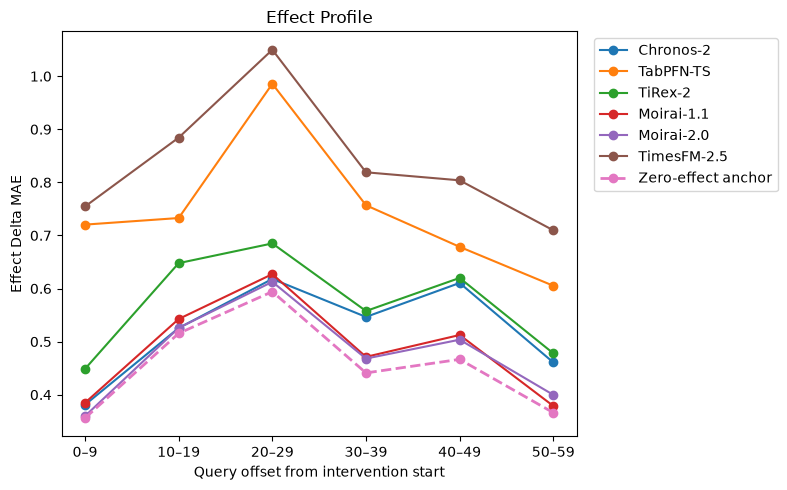

In [17]:
# (a) During intervention
fig, ax = plt.subplots(figsize=(8, 5))
for j, model in enumerate(MODELS):
    vals = profile_data("in_window", model)
    ax.plot(IN_LABELS, [vals[b][0] for b in IN_LABELS], marker="o", color=f"C{j}", label=DISPLAY[model])
ax.plot(IN_LABELS, [anchor_in[b][0] for b in IN_LABELS], marker="o", linestyle="--",
        linewidth=2, color="C6", label="Zero-effect anchor")
ax.set(title="Effect Profile", xlabel="Query offset from intervention start", ylabel="Effect Delta MAE")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGURES / f"figure1a_in_window.{ext}", dpi=300, bbox_inches="tight")
plt.show()

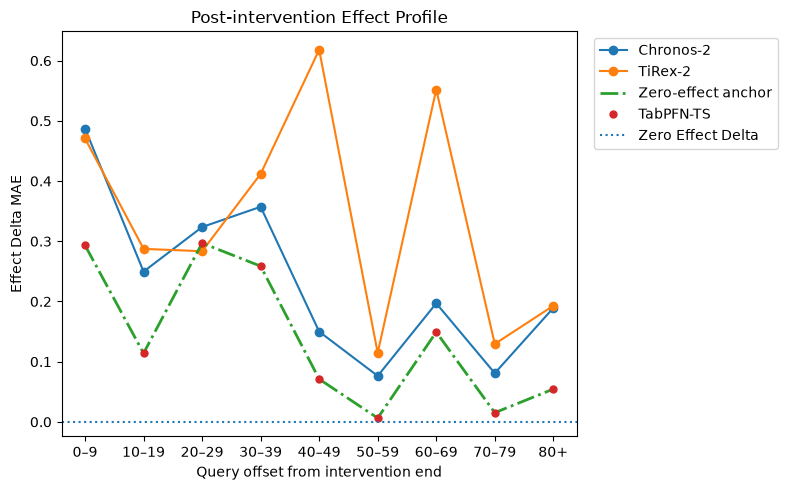

In [18]:
# (b) After intervention
fig, ax = plt.subplots(figsize=(8, 5))
for j, model in enumerate(["chronos-2", "tirex-2"]):
    vals = profile_data("post_window", model)
    ax.plot(POST_LABELS, [vals[b][0] for b in POST_LABELS], marker="o", color=f"C{j}", label=DISPLAY[model])
ax.plot(POST_LABELS, [anchor_post[b][0] for b in POST_LABELS], linestyle="-.",
        linewidth=2, color="C2", label="Zero-effect anchor")
tabpfn = profile_data("post_window", "tabpfn-ts")
ax.plot(POST_LABELS, [tabpfn[b][0] for b in POST_LABELS], marker="o", linestyle="none",
        markersize=5, color="C3", label="TabPFN-TS")
ax.axhline(0, linestyle=":", color="C0", label="Zero Effect Delta")
ax.set(title="Post-intervention Effect Profile", xlabel="Query offset from intervention end",
       ylabel="Effect Delta MAE")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGURES / f"figure1b_post_window.{ext}", dpi=300, bbox_inches="tight")
plt.show()

## Across-seed variability (Appendix E.6)

Moirai-1.1 is the only model run under three inference seeds. Standard
deviations across seeds, on the same populations as Tables 1 and 7.

In [19]:
ident_seed = row("moirai-1.1", "identifiability", pooled_nz)
cont_seed = row("moirai-1.1", "in_window")
seed_var = pd.DataFrame({
    "Identifiability": [ident_seed.usage_gap_seed_std, ident_seed.effect_rmse_seed_std],
    "Continuous in-window": [cont_seed.usage_gap_seed_std, cont_seed.effect_rmse_seed_std],
}, index=["Usage Gap", "Effect Delta RMSE"])
display(seed_var.round(4))

,Identifiability,Continuous in-window
Usage Gap,0.0011,0.0064
Effect Delta RMSE,0.0015,0.2132
